# Proyecto Sprint 8 - Zuber: Análisis de viajes compartidos en Chigago

### **Introducción**

Este análisis examina el mercado de viajes compartidos en Chicago para Zuber, una nueva empresa que busca establecerse en este sector. A través del estudio de datos de competidores y factores externos, se identificaron dos patrones clave que definen el panorama competitivo: la existencia de un oligopolio donde las empresas líderes controlan aproximadamente tres cuartas partes del mercado, y el impacto significativo de las condiciones climáticas en la duración de los viajes, particularmente durante días lluviosos.


## Paso 1: Análisis del clima en Chigago

Código para analizar los datos sobre el clima en Chicago en noviembre de 2017 desde el sitio web:
https://practicum-content.s3.us-west-1.amazonaws.com/data-analyst-eng/moved_chicago_weather_2017.html

In [1]:
import pandas as pd
import requests
from bs4 import BeautifulSoup

URL ='https://practicum-content.s3.us-west-1.amazonaws.com/data-analyst-eng/moved_chicago_weather_2017.html'
req= requests.get(URL)
soup = BeautifulSoup(req.text, 'lxml')

table = soup.find('table', attrs={'id': 'weather_records'})#busqueda de la tabla 

heading_table = []#extracción de encabezados
for row in table.find_all('th'):
    heading_table.append(row.text)

content = []#extracción de contenido de las filas
for row in table.find_all('tr'):
    if not row.find_all('th'):
        content.append([element.text for element in row.find_all('td')])
        
#creacion del DataFrame
weather_records = (
    pd.DataFrame(data= content, columns = heading_table))

print(weather_records)

           Date and time Temperature       Description
0    2017-11-01 00:00:00     276.150     broken clouds
1    2017-11-01 01:00:00     275.700  scattered clouds
2    2017-11-01 02:00:00     275.610   overcast clouds
3    2017-11-01 03:00:00     275.350     broken clouds
4    2017-11-01 04:00:00     275.240     broken clouds
..                   ...         ...               ...
692  2017-11-29 20:00:00     281.340        few clouds
693  2017-11-29 21:00:00     281.690      sky is clear
694  2017-11-29 22:00:00     281.070        few clouds
695  2017-11-29 23:00:00     280.060      sky is clear
696  2017-11-30 00:00:00     278.460      sky is clear

[697 rows x 3 columns]


## Paso 2: Análisis exploratorio de datos

Encontrar el número de viajes en taxi para cada empresa de taxis del 15 al 16 de noviembre de 2017. Nombrar el campo resultante trips_amount y mostrarlo junto con el campo company_name. Ordenar los resultados por el campo trips_amount en orden descendente.


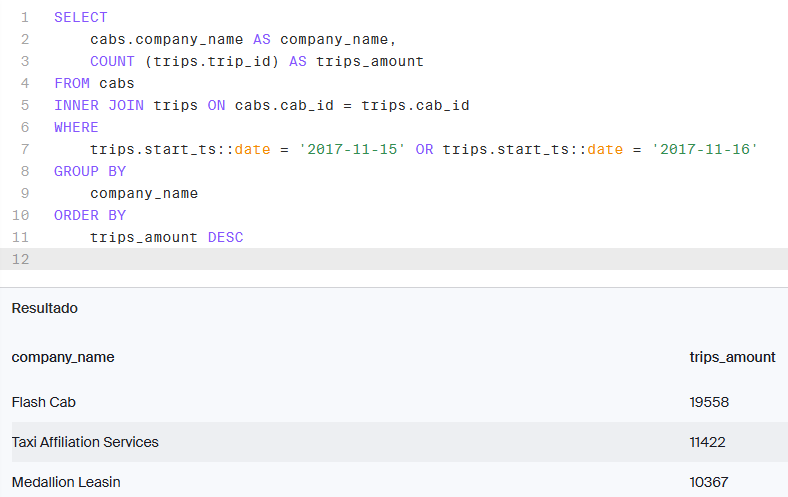

Encontrar la cantidad de viajes para cada empresa de taxis cuyo nombre contenga las palabras "Yellow" o "Blue" del 1 al 7 de noviembre de 2017. Nombrar la variable resultante trips_amount. Agrupar los resultados por el campo company_name.
En noviembre de 2017 las empresas de taxis más populares fueron Flash Cab y Taxi Affiliation Services. 

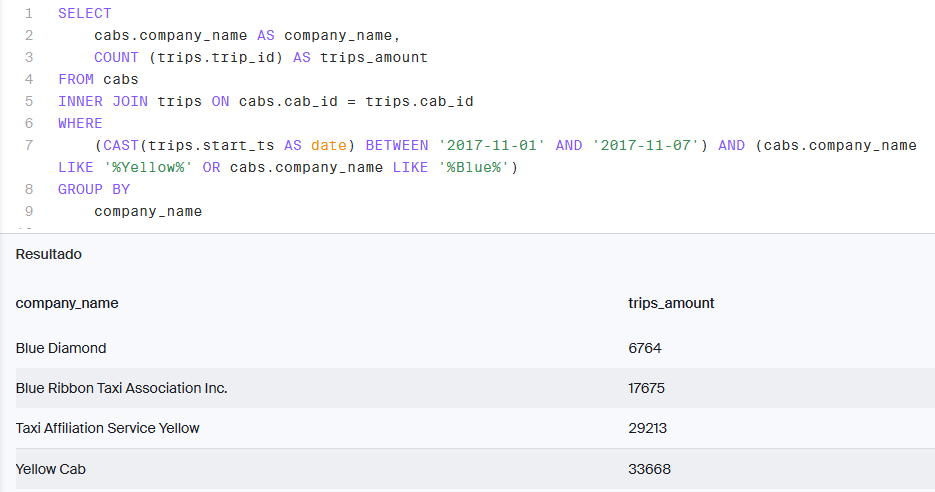

Encontrar el número de viajes de estas dos empresas y asignar a la variable resultante el nombre trips_amount. Juntar los viajes de todas las demás empresas en el grupo "Other". Agrupar los datos por nombres de empresas de taxis. Nombrar el campo con nombres de empresas de taxis company. Ordenar el resultado en orden descendente por trips_amount.

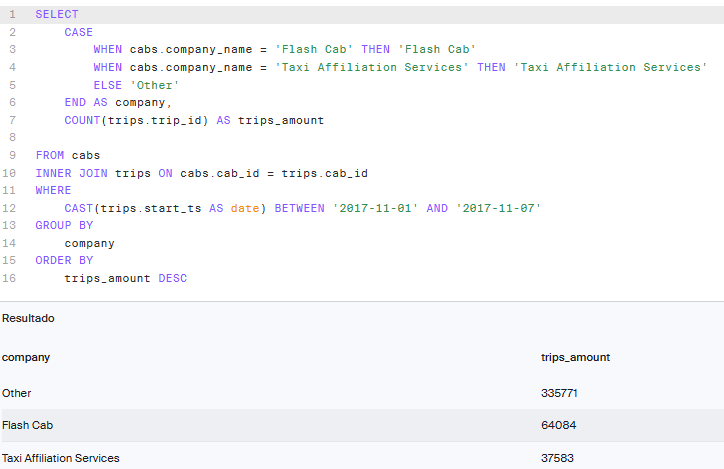

## Paso 3.  Exploracion inicial para prueba de hipótesis de que la duración de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare cambia los sábados lluviosos.

Recuperar los identificadores de los barrios de O'Hare y Loop de la tabla neighborhoods.

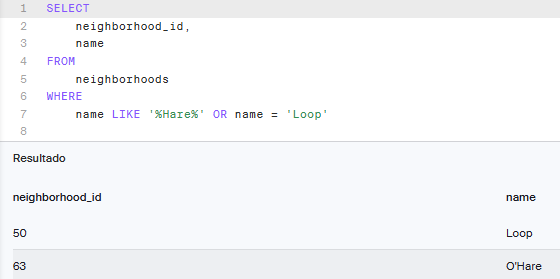

Para cada hora recuperar los registros de condiciones meteorológicas de la tabla weather_records. Usando el operador CASE, dividir todas las horas en dos grupos: "Bad" si el campo description contiene las palabras "rain" o "storm" y "Good" para los demás. Nombrar el campo resultante weather_conditions. La tabla final debe incluir dos campos: fecha y hora (ts) y weather_conditions.

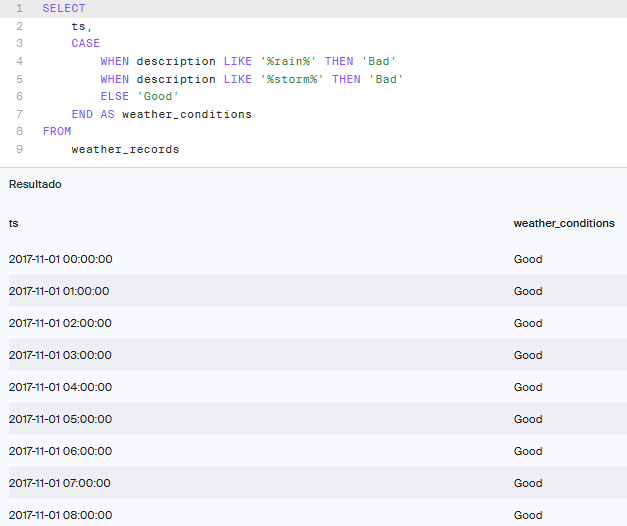

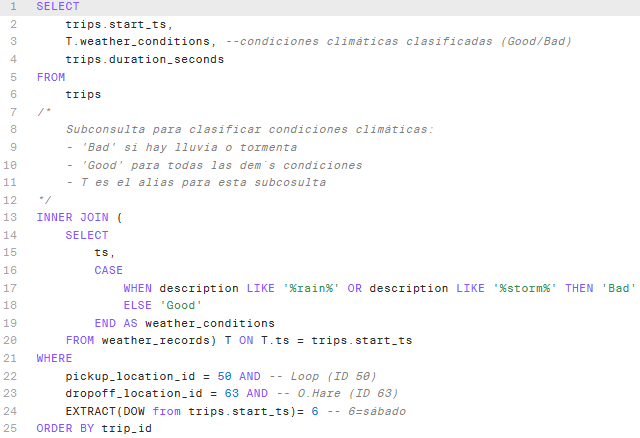
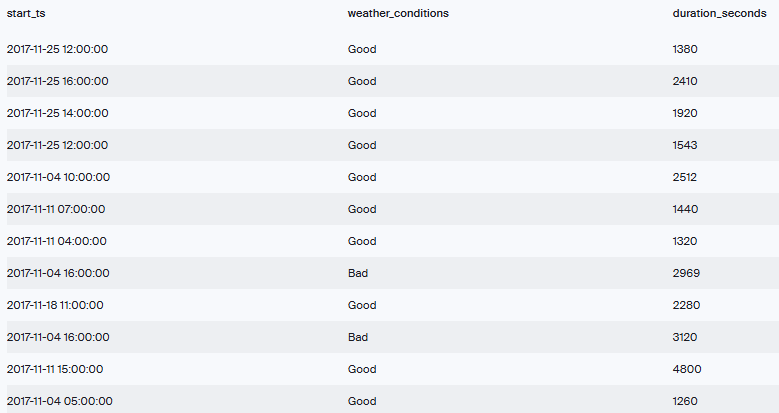

## Paso 4. Análisis exploratorio de datos (Python)

Además de los datos que recuperamos en las tareas anteriores. Ahora tenemos estos dos CSV:

### project_sql_result_01.csv. Contiene los siguientes datos:

company_name: nombre de la empresa de taxis
trips_amount: el número de viajes de cada compañía de taxis el 15 y 16 de noviembre de 2017.

### project_sql_result_04.csv. Contiene los siguientes datos:

dropoff_location_name: barrios de Chicago donde finalizaron los viajes
average_trips: el promedio de viajes que terminaron en cada barrio en noviembre de 2017.

Para estos dos datasets ahora necesitaremos:

Importar los archivos.
Estudiar los datos que contienen.
Asegurarnos de que los tipos de datos sean correctos.
Identificar los 10 principales barrios en términos de finalización.
Hacer gráficos: empresas de taxis y número de viajes, los 10 barrios principales por número de finalizaciones.
Sacar conclusiones basadas en cada gráfico y explicar los resultados.

## 4.1 Imports básicos

In [2]:
# Cargar todas las librerías
import pandas as pd
import math
import numpy as np
from scipy import stats as st
import seaborn as sns
from matplotlib import pyplot as plt
import plotly.express as px

## 4.2 Preparación de Datos

### 4.2.1 Carga de Archivos de Datos

In [3]:
df_company = pd.read_csv('/datasets/project_sql_result_01.csv', sep=',', encoding= 'utf-8', quotechar= '"')
df_trips = pd.read_csv('/datasets/project_sql_result_04.csv', sep=',', encoding= 'utf-8', quotechar= '"')

### 4.2.2 Exploracion df_company

In [4]:
# Información general/resumida sobre el DataFrame de las compañias
print("===INFORMACION BÁSICA===")
print("Forma del DataFrame:", df_company.shape)
print("Columnas:", df_company.columns.tolist())
print("Tipos de datos:", df_company.dtypes)
print()
# Verificar valores nulos
print("Valores nulos por columna:")
print(df_company.isnull().sum())
print()
# Verificar duplicados
duplicados = df_company.duplicated().sum()
print(f"filas duplicadas: {duplicados}")
print()
print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(df_company.describe())
print()
# Vista general
print("===VISTA DEL DATAFRAME===")
display(df_company.head(15))


===INFORMACION BÁSICA===
Forma del DataFrame: (64, 2)
Columnas: ['company_name', 'trips_amount']
Tipos de datos: company_name    object
trips_amount     int64
dtype: object

Valores nulos por columna:
company_name    0
trips_amount    0
dtype: int64

filas duplicadas: 0


=== ESTADÍSTICAS DESCRIPTIVAS ===
       trips_amount
count     64.000000
mean    2145.484375
std     3812.310186
min        2.000000
25%       20.750000
50%      178.500000
75%     2106.500000
max    19558.000000

===VISTA DEL DATAFRAME===


,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasing,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299
5,Chicago Carriage Cab Corp,9181
6,City Service,8448
7,Sun Taxi,7701
8,Star North Management LLC,7455
9,Blue Ribbon Taxi Association Inc.,5953


### 4.2.3 Exploración df_trips

In [5]:
# Información general/resumida sobre el DataFrame de los viajes

print("===INFORMACION BÁSICA===")
print("Forma del DataFrame:", df_trips.shape)
print("Columnas:", df_trips.columns.tolist())
print("Tipos de datos:", df_trips.dtypes)
print()
# Verificar valores nulos
print("Valores nulos por columna:")
print(df_trips.isnull().sum())
print()
# Verificar duplicados
duplicados = df_trips.duplicated().sum()
print(f"filas duplicadas: {duplicados}")
print()
print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(df_trips.describe())
print()
# Vista general
print("===VISTA DEL DATAFRAME===")
display(df_trips.head(15))


===INFORMACION BÁSICA===
Forma del DataFrame: (94, 2)
Columnas: ['dropoff_location_name', 'average_trips']
Tipos de datos: dropoff_location_name     object
average_trips            float64
dtype: object

Valores nulos por columna:
dropoff_location_name    0
average_trips            0
dtype: int64

filas duplicadas: 0


=== ESTADÍSTICAS DESCRIPTIVAS ===
       average_trips
count      94.000000
mean      599.953728
std      1714.591098
min         1.800000
25%        14.266667
50%        52.016667
75%       298.858333
max     10727.466667

===VISTA DEL DATAFRAME===


,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000
5,Lake View,2420.966667
6,Grant Park,2068.533333
7,Museum Campus,1510.000000
8,Gold Coast,1364.233333
9,Sheffield & DePaul,1259.766667


### Observaciones iniciales
Ambos data sets son extracciones SQL de una base de datos, por lo tanto, no tenemos ningun problema de tipos de datos incorrectos, sin filas duplicadas ni valores nulos, lo que nos permitirá trabajar nuestro análisis de manera más ágil. 

## 4.3. Identificar los 10 principales barrios en términos de finalización

In [6]:
#Crear variable con los 10 barrios principales 
top_10_neighborhoods = df_trips.nlargest(10, 'average_trips')
display(top_10_neighborhoods)

,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000
5,Lake View,2420.966667
6,Grant Park,2068.533333
7,Museum Campus,1510.000000
8,Gold Coast,1364.233333
9,Sheffield & DePaul,1259.766667


## 4.4. Gráficos

### 4.4.1 Gráficos de distribución de empresas de taxis y número de viajes

**Estrategia de segmentación**

Debido a que tenemos conteos con variación considerable, se segmentarán por grupos en funcion del numero de viajes de cada empresa, para que en base a ello se obtengan gráficos más eficientes. Tendremos las siguientes categorías:

- **Individuales**: Empresas con 5,000+ viajes (se mostrarán en un gráfico por separado).
- **Grupo "1,000-4,999 viajes"**: Empresas entre 1,000 y 4,999 viajes.
- **Grupo "100-999 viajes"**: Empresas entre 100 y 999 viajes.
- **Grupo "Menos de 100 viajes"**: Empresas con menos de 100 viajes.

In [7]:
# Analizar la distribución por rangos

# Empresas con mas de 5000 viajes
print("Empresas con 5000+ viajes:")
empresas_top = df_company[df_company['trips_amount'] >= 5000]
print(f"Cantidad: {len(empresas_top)}")
print(empresas_top[['company_name', 'trips_amount']])


Empresas con 5000+ viajes:
Cantidad: 11
                         company_name  trips_amount
0                           Flash Cab         19558
1           Taxi Affiliation Services         11422
2                   Medallion Leasing         10367
3                          Yellow Cab          9888
4     Taxi Affiliation Service Yellow          9299
5           Chicago Carriage Cab Corp          9181
6                        City Service          8448
7                            Sun Taxi          7701
8           Star North Management LLC          7455
9   Blue Ribbon Taxi Association Inc.          5953
10            Choice Taxi Association          5015


Observamos a 11 empresas con un conteo mayor a 5000 viajes, de las cuales el listado lo encabeza "Flash Cab" con 19558 viajes y en último lugar está la empesa "Choice Taxi Association" con 5015 viajes.

In [8]:
# Empresas en el rango 1,001-4,999 viajes
empresas_medio = df_company[(df_company['trips_amount'] >= 1000) & (df_company['trips_amount'] < 5000)]
print("Empresas con 1,000-4,999 viajes:")
print(f"Cantidad: {len(empresas_medio)}")
print(empresas_medio[['company_name', 'trips_amount']])
print(f"Total de viajes del grupo: {empresas_medio['trips_amount'].sum()}")

Empresas con 1,000-4,999 viajes:
Cantidad: 14
                               company_name  trips_amount
11                               Globe Taxi          4383
12                Dispatch Taxi Affiliation          3355
13                Nova Taxi Affiliation Llc          3175
14  Patriot Taxi Dba Peace Taxi Association          2235
15                 Checker Taxi Affiliation          2216
16                             Blue Diamond          2070
17             Chicago Medallion Management          1955
18                            24 Seven Taxi          1775
19            Chicago Medallion Leasing INC          1607
20                             Checker Taxi          1486
21                          American United          1404
22                     Chicago Independents          1296
23                    KOAM Taxi Association          1259
24                          Chicago Taxicab          1014
Total de viajes del grupo: 29230


En la categoría de 1000 a 5000 viajes, tenemos a 14 empresas, encabezando el listado "Globe Taxi" en primer lugar y en último lugar con 1014 viajes la empresa "Chigago Taxicab".

In [9]:
# Empresas en el rango 100-999 viajes
empresas_pequenas = df_company[(df_company['trips_amount'] >= 100) & (df_company['trips_amount'] < 1000)]
print("Empresas con 100-999 viajes:")
print(f"Cantidad: {len(empresas_pequenas)}")
print(empresas_pequenas[['company_name','trips_amount']])
print(f"Total de viajes del grupo: {empresas_pequenas['trips_amount'].sum()}")

print("\n" + "="*50 + "\n")

# Empresas con menos de 100 viajes
empresas_muy_pequenas = df_company[df_company['trips_amount'] < 100]
print("Empresas con menos de 100 viajes:")
print(f"Cantidad: {len(empresas_muy_pequenas)}")
print(empresas_muy_pequenas[['company_name','trips_amount']])
print(f"Total de viajes del grupo: {empresas_muy_pequenas['trips_amount'].sum()}")

Empresas con 100-999 viajes:
Cantidad: 10
                        company_name  trips_amount
25               Top Cab Affiliation           978
26                   Gold Coast Taxi           428
27          Service Taxi Association           402
28                       5 Star Taxi           310
29                          303 Taxi           250
30                        Setare Inc           230
31  American United Taxi Affiliation           210
32                    Leonard Cab Co           147
33                  Metro Jet Taxi A           146
34                      Norshore Cab           127
Total de viajes del grupo: 3228


Empresas con menos de 100 viajes:
Cantidad: 29
                          company_name  trips_amount
35         6742 - 83735 Tasha Ride Inc            39
36              3591 - 63480 Chuks Cab            37
37              1469 - 64126 Omar Jada            36
38             6743 - 78771 Luhak Corp            33
39        0118 - 42111 Godfrey S. Awir            3

En la categoría de 100 a 999 viajes tenemos un total de 10 empresas.
En la categoría de empresas con menos de 100 viajes tenemos un total de 29 empresas.
Ahora vamos a crear una tabla dinámica con los 4 grupos que identificamos para poder visualizar mejor la distribución de las empresas por rangos de viajes

In [10]:
# Crear una copia del DataFrame para trabajar
df_segmented = df_company.copy()

# Crear la columna de categorías
def categorizar_empresa(trips):
    if trips >= 5000:
        return 'Individual (5,000+ viajes)'
    elif trips >= 1000:
        return 'Grupo 1,000-4,999 viajes'
    elif trips >= 100:
        return 'Grupo 100-999 viajes'
    else:
        return 'Grupo <100 viajes'

df_segmented['categoria'] = df_segmented['trips_amount'].apply(categorizar_empresa)
print("DataFrame con categorías:")
print(df_segmented.head())

DataFrame con categorías:
                      company_name  trips_amount                   categoria
0                        Flash Cab         19558  Individual (5,000+ viajes)
1        Taxi Affiliation Services         11422  Individual (5,000+ viajes)
2                Medallion Leasing         10367  Individual (5,000+ viajes)
3                       Yellow Cab          9888  Individual (5,000+ viajes)
4  Taxi Affiliation Service Yellow          9299  Individual (5,000+ viajes)


In [11]:
# Crear tabla dinámica para mejor visualización
tabla_dinamica = df_segmented.groupby('categoria').agg({
    'company_name': 'count',  # Número de empresas
    'trips_amount': 'sum'     # Total de viajes
}).rename(columns={
    'company_name': 'num_empresas',
    'trips_amount': 'total_viajes'
})

# Agregar porcentajes
tabla_dinamica['porcentaje_viajes'] = (tabla_dinamica['total_viajes'] / tabla_dinamica['total_viajes'].sum() * 100).round(2)

print("Tabla Dinámica:")
display(tabla_dinamica)

Tabla Dinámica:


,num_empresas,total_viajes,porcentaje_viajes
categoria,,,
"Grupo 1,000-4,999 viajes",14,29230,21.29
Grupo 100-999 viajes,10,3228,2.35
Grupo <100 viajes,29,566,0.41
"Individual (5,000+ viajes)",11,104287,75.95


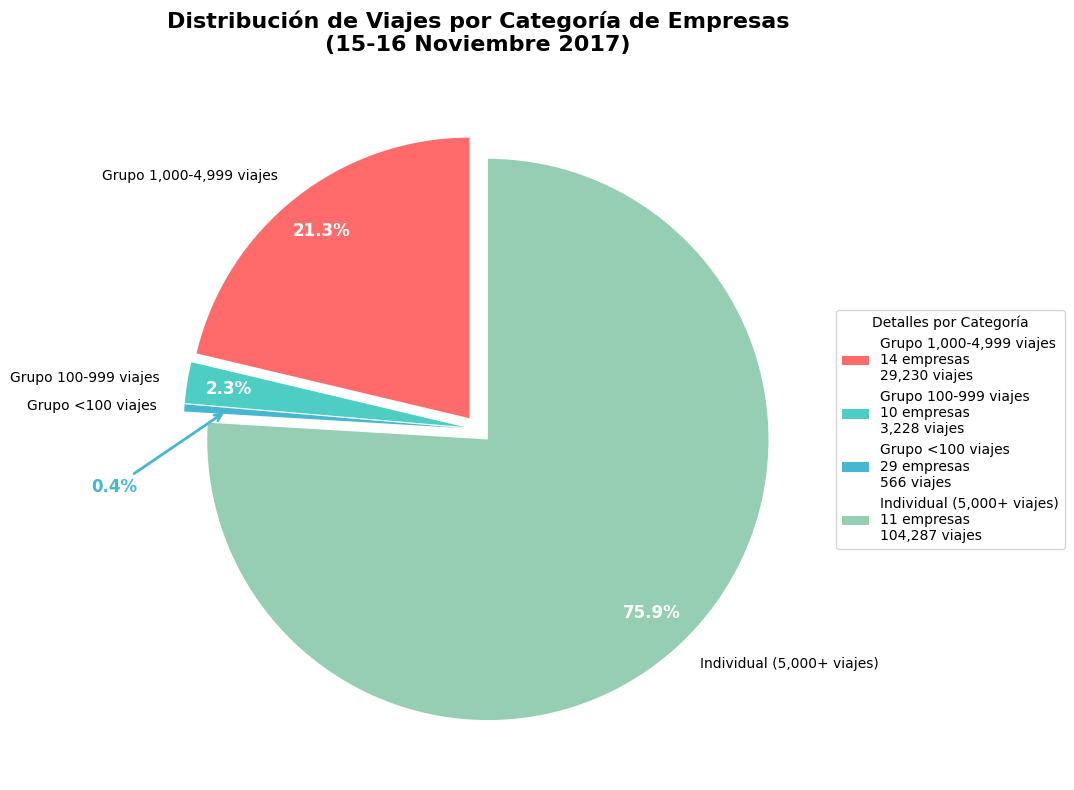


=== TABLA DINÁMICA DE REFERENCIA ===


,num_empresas,total_viajes,porcentaje_viajes
categoria,,,
"Grupo 1,000-4,999 viajes",14,29230,21.29
Grupo 100-999 viajes,10,3228,2.35
Grupo <100 viajes,29,566,0.41
"Individual (5,000+ viajes)",11,104287,75.95


In [12]:
# Gráfico de pastel mejorado con etiqueta externa para porcentajes pequeños
plt.figure(figsize=(12, 8))

# Usar los datos de la tabla dinámica
categorias = tabla_dinamica.index
porcentajes = tabla_dinamica['porcentaje_viajes']
total_viajes = tabla_dinamica['total_viajes']

# Definir colores para cada categoría
colores = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']

# Función personalizada para mostrar porcentajes
def autopct_format(pct):
    if pct < 1.0:  # Si es menor al 1%, no mostrar texto dentro
        return ''
    else:
        return f'{pct:.1f}%'

# Crear el gráfico de pastel
wedges, texts, autotexts = plt.pie(porcentajes, 
                                   labels=categorias,
                                   colors=colores,
                                   autopct=autopct_format,  # Función personalizada
                                   startangle=90,
                                   explode=(0.05, 0.05, 0.05, 0.05),
                                   pctdistance=0.85)

# Personalizar el gráfico
plt.title('Distribución de Viajes por Categoría de Empresas\n(15-16 Noviembre 2017)', 
          fontsize=16, fontweight='bold', pad=20)

# Mejorar la apariencia del texto interno
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(12)
    autotext.set_fontweight('bold')

# Agregar etiqueta externa para el porcentaje pequeño (Grupo <100 viajes)
# Encontrar el índice del grupo <100 viajes
idx_pequeno = list(categorias).index('Grupo <100 viajes')
wedge_pequeno = wedges[idx_pequeno]

# Calcular la posición para la etiqueta externa
angle = (wedge_pequeno.theta1 + wedge_pequeno.theta2) / 2
x = 1.3 * np.cos(np.radians(angle))
y = 1.3 * np.sin(np.radians(angle))
 
# Agregar la etiqueta externa con flecha
plt.annotate(f'{porcentajes.iloc[idx_pequeno]:.1f}%', 
             xy=(0.9 * np.cos(np.radians(angle)), 0.9 * np.sin(np.radians(angle))),
             xytext=(x, y - 0.3),
             ha='center', va='center',
             fontsize=12, fontweight='bold',
             color=colores[idx_pequeno],  # Mismo color que la rebanada
             arrowprops=dict(arrowstyle='->', 
                           connectionstyle='arc3,rad=0',
                           color=colores[idx_pequeno],
                           lw=2))

# Crear una leyenda con información adicional
leyenda_labels = []
for i, categoria in enumerate(categorias):
    num_empresas = tabla_dinamica.loc[categoria, 'num_empresas']
    viajes = tabla_dinamica.loc[categoria, 'total_viajes']
    leyenda_labels.append(f'{categoria}\n{num_empresas} empresas\n{viajes:,} viajes')

plt.legend(wedges, leyenda_labels, 
          title="Detalles por Categoría",
          loc="center left", 
          bbox_to_anchor=(1, 0, 0.5, 1))

plt.tight_layout()
plt.show()

# Mostrar también la tabla dinámica para referencia
print("\n=== TABLA DINÁMICA DE REFERENCIA ===")
display(tabla_dinamica)

#### Conclusiones del Grafico "Distribución de Viajes por Categoría de Empresas" (15 - 16 Noviembre 2017)

**Observación Principal:**
El mercado de taxis en Chicago presenta una alta concentración, donde sólo 11 empresas individuales (17% del total) controlan el 75.95% de todos los viajes realizados el 15 y 16 de Noviembre de 2017.

**Datos Específicos**
- 11 empresas individuales: 104,287 viajes (75.95%)
- 14 empresas medianas: 29,230 viajes (21.29%)
- 10 empresas pequeñas: 3.228 viajes (2.35%)
- 29 empresas muy pequeñas: 566 viajes (0.41%)

**Patrón Identificado**
Concentración extrema del mercado en pocas empresas grandes.

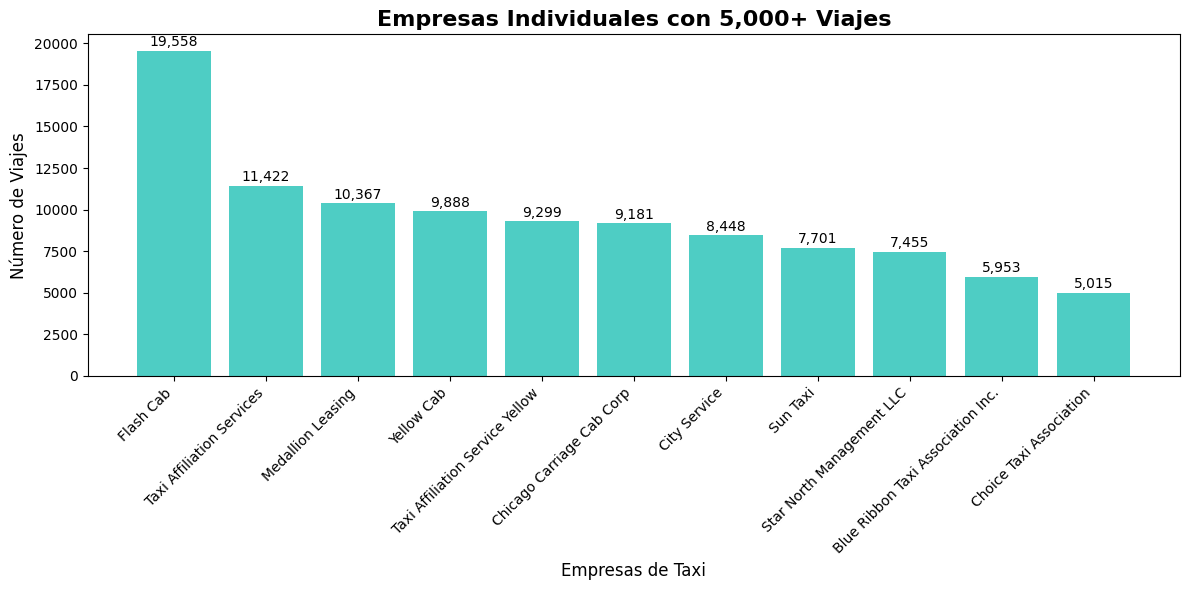

In [13]:
# Gráfico 1: Solo empresas individuales
plt.figure(figsize=(12, 6))

# Filtrar solo empresas con 5000+ viajes
empresas_individuales = df_company[df_company['trips_amount'] >= 5000].sort_values('trips_amount', ascending=False)


# Crear el gráfico de barras
bars = plt.bar(range(len(empresas_individuales)), 
               empresas_individuales['trips_amount'], 
               color='#4ECDC4')


# Personalizar el gráfico
plt.title('Empresas Individuales con 5,000+ Viajes', fontsize=16, fontweight='bold')
plt.xlabel('Empresas de Taxi', fontsize=12)
plt.ylabel('Número de Viajes', fontsize=12)
plt.xticks(range(len(empresas_individuales)), 
           empresas_individuales['company_name'], 
           rotation=45, ha='right')

# Agregar valores en las barras
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 100,
             f'{int(height):,}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

#### Conclusiones del Gráfico Empresas Individuales con 5,000+ Viajes (Empresas Líderes del Mercado)

**Observación principal**
Flash Cab domina claramente el mercado con 19,558 viajes, seguido por Taxi Affiliation Services con 11,422 viajes.

**Datos Específicos**
- Flash Cab: 19,588 viajes (líder indiscutible)
- Top 3 de empresas concentran: 41,347 viajes (30% del mercado total)
- Diferencia sigfnificativa entre líder y segundo lugar: 8,136 viajes.

**Implicaciones para Zuber:**
- Flash Cab es el competidor principal a analizar
- Necesisdad de estrategias diferenciadas para competir
- Oportunidad de alianzas con empresas medianas

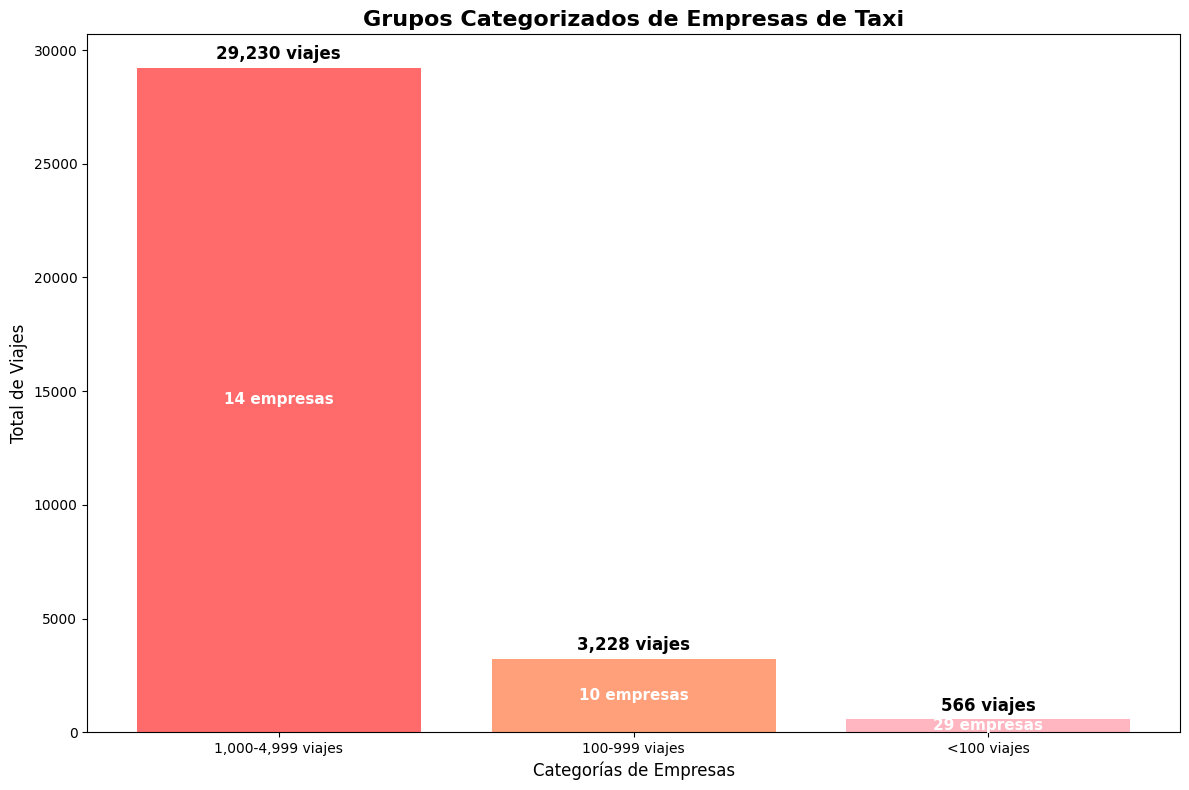


=== RESUMEN DE GRUPOS CATEGORIZADOS ===
         categoria  total_viajes  num_empresas
1,000-4,999 viajes         29230            14
    100-999 viajes          3228            10
       <100 viajes           566            29


In [14]:
# Gráfico 2: Grupos categorizados con información adicional
plt.figure(figsize=(12, 8))

# Preparar los datos para los grupos categorizados (sin empresas individuales)
grupos_info = []

# Grupo 1,000-4,999 viajes
grupo_medio = df_company[(df_company['trips_amount'] >= 1000) & (df_company['trips_amount'] < 5000)]
grupos_info.append({
    'categoria': '1,000-4,999 viajes',
    'total_viajes': grupo_medio['trips_amount'].sum(),
    'num_empresas': len(grupo_medio)
})

# Grupo 100-999 viajes  
grupo_pequeno = df_company[(df_company['trips_amount'] >= 100) & (df_company['trips_amount'] < 1000)]
grupos_info.append({
    'categoria': '100-999 viajes',
    'total_viajes': grupo_pequeno['trips_amount'].sum(),
    'num_empresas': len(grupo_pequeno)
})

# Grupo <100 viajes
grupo_muy_pequeno = df_company[df_company['trips_amount'] < 100]
grupos_info.append({
    'categoria': '<100 viajes',
    'total_viajes': grupo_muy_pequeno['trips_amount'].sum(),
    'num_empresas': len(grupo_muy_pequeno)
})

# Convertir a DataFrame
df_grupos_info = pd.DataFrame(grupos_info)

# Crear el gráfico de barras
bars = plt.bar(range(len(df_grupos_info)), 
               df_grupos_info['total_viajes'], 
               color=['#FF6B6B', '#FFA07A', '#FFB6C1'])

# Personalizar el gráfico
plt.title('Grupos Categorizados de Empresas de Taxi', fontsize=16, fontweight='bold')
plt.xlabel('Categorías de Empresas', fontsize=12)
plt.ylabel('Total de Viajes', fontsize=12)
plt.xticks(range(len(df_grupos_info)), df_grupos_info['categoria'])

# Agregar información en las barras (total de viajes y número de empresas)
for i, bar in enumerate(bars):
    height = bar.get_height()
    num_empresas = df_grupos_info.iloc[i]['num_empresas']
    
    # Texto principal: total de viajes
    plt.text(bar.get_x() + bar.get_width()/2., height + 200,
             f'{int(height):,} viajes', ha='center', va='bottom', 
             fontsize=12, fontweight='bold')
    
    # Texto secundario: número de empresas
    plt.text(bar.get_x() + bar.get_width()/2., height/2,
             f'{num_empresas} empresas', ha='center', va='center', 
             fontsize=11, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

# Mostrar tabla resumen
print("\n=== RESUMEN DE GRUPOS CATEGORIZADOS ===")
print(df_grupos_info.to_string(index=False))

### 4.4.2 Gráficos de distribución de los barrios principales y el promedio de viajes a esos barrios

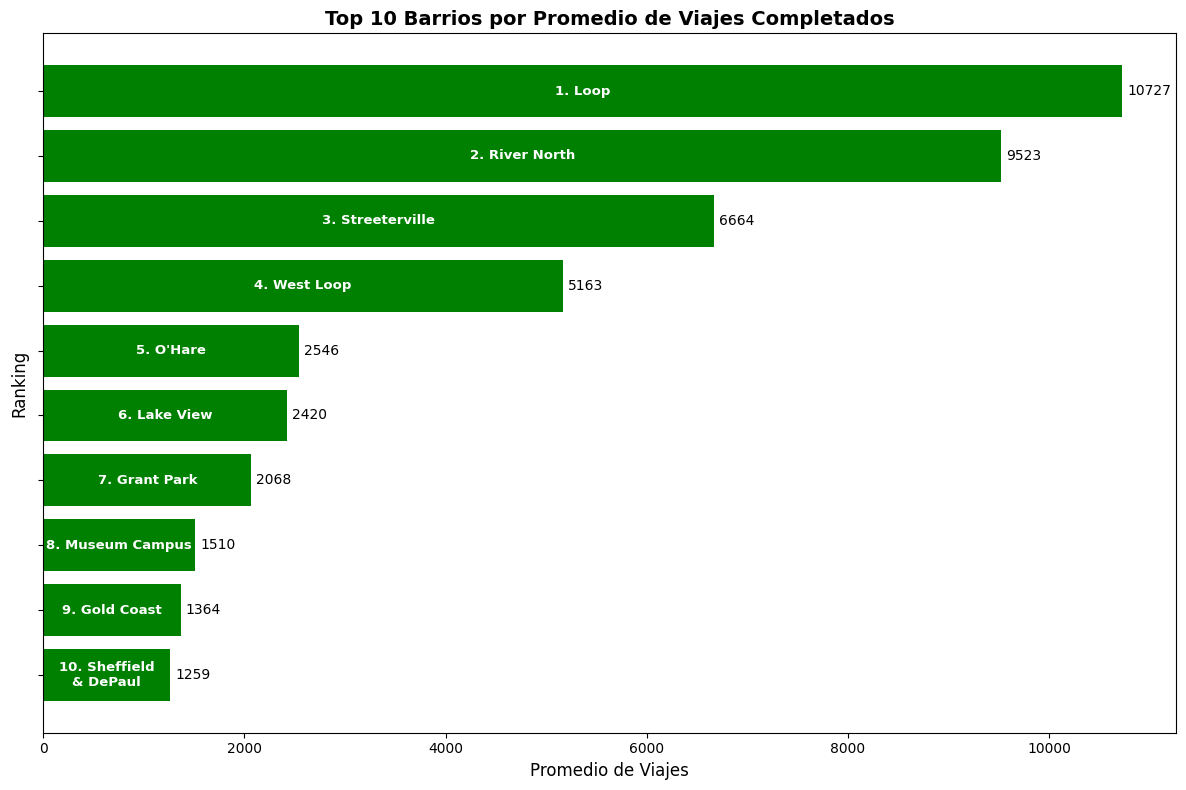

In [15]:
# Función para dividir el nombre "Sheffield & DePaul" para mejor visualizacion
def dividir_nombre_largo(nombre, max_chars=15):
    """
    Divide nombre en dos líneas
    """
    if len(nombre) <= max_chars:
        return nombre

    # Tiene '&', así que se va a dividir por ahí
    if '&' in nombre:
        partes = nombre.split('&')
        return f"{partes[0].strip()}\n& {partes[1].strip()}"
        
    return nombre

# Gráfico de barras horizontales del top 10 de Barrios 
plt.figure(figsize=(12,8))

# Ordenar los datos de mayor a menor (descendente)
top_10_sorted = top_10_neighborhoods.sort_values('average_trips', ascending=False)

# Invertir las posiciones para que Loop esté arriba
posiciones_y = list(range(10, 0, -1))  # [10, 9, 8, 7, 6, 5, 4, 3, 2, 1]

# Crear las barras horizontales
bars = plt.barh(posiciones_y, top_10_sorted['average_trips'], color='green')

# QUITAR los números del eje Y - solo mostrar las posiciones sin etiquetas
plt.yticks(posiciones_y, [''] * len(posiciones_y))

# Agregar los valores al final de cada barra
for i, bar in enumerate(bars):
    width = bar.get_width()
    plt.text(width + 50, bar.get_y() + bar.get_height()/2,
             f'{int(width)}', ha='left', va='center', fontsize=10)

# Agregar los números Y nombres de los barrios DENTRO de cada barra
for i, bar in enumerate(bars):
    width = bar.get_width()
    neighborhood_name = top_10_sorted.iloc[i]['dropoff_location_name']
    ranking_number = i + 1  # El número de ranking (1, 2, 3, etc.)
    
    # Usar la función para dividir el nombre largo
    nombre_dividido = dividir_nombre_largo(neighborhood_name)
    texto_completo = f"{ranking_number}. {nombre_dividido}"
    
    plt.text(width/2, bar.get_y() + bar.get_height()/2,
             texto_completo, ha='center', va='center',
             fontsize=9.5, color='white', fontweight='bold')

plt.title('Top 10 Barrios por Promedio de Viajes Completados', fontsize=14, fontweight='bold')
plt.xlabel('Promedio de Viajes', fontsize=12)
plt.ylabel('Ranking', fontsize=12)
plt.tight_layout()
plt.show()

#### Conclusiones del Gráfico Top 10 Barrios por promedio de viajes completados (Destinos más populares en Chicago)

**Observación Principal:**
Loop es el destino más popular con 10,727 viajes promedio, superando significativamente a otros barrios.

**Datos Específicos:**
- Loop: 10,727 viajes (destino #1)
- River North: 9523 viajes (destino #2)
- Streeterville: 6664 (deestino #3)

**Patrón Identificado:**
Concentración de demanda en el distrito financiero y zonas comerciales centrales.

**Implicaciones para Zuber:**
- Priorizar cobertura en Loop y River North
- Enfocar estrategia de marketing en zonas de alta demanda
- Considerar tarifas dinámicas en destinos populares

## Paso 5. Prueba de hipótesis (Python)

project_sql_result_07.csv: el resultado de la última consulta. Contiene datos sobre viajes desde el Loop hasta el Aeropuerto Internacional O'Hare. 

Estos son los valores de campo de la tabla:

start_ts: fecha y hora de recogida
weather_conditions: condiciones climáticas en el momento en el que comenzó el viaje
duration_seconds: duración del viaje en segundos


### 5.1 Carga de Archivo de Datos y exploración 

In [16]:
df_loop_ohare = pd.read_csv('/datasets/project_sql_result_07.csv', sep=',', encoding= 'utf-8', quotechar= '"')

In [17]:

# Información general/resumida sobre el DataFrame de viajes entre el Loop y O'Hare
print("===INFORMACION BÁSICA===")
print("Forma del DataFrame:", df_loop_ohare.shape)
print("Columnas:", df_loop_ohare.columns.tolist())
print("Tipos de datos:", df_loop_ohare.dtypes)
print()
# Verificar valores nulos
print("Valores nulos por columna:")
print(df_loop_ohare.isnull().sum())
print()
# Verificar duplicados
duplicados = df_loop_ohare.duplicated().sum()
print(f"filas duplicadas: {duplicados}")
print()
print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(df_loop_ohare.describe())
print()
# Vista general
print("===VISTA DEL DATAFRAME===")
display(df_loop_ohare.head(15))


===INFORMACION BÁSICA===
Forma del DataFrame: (1068, 3)
Columnas: ['start_ts', 'weather_conditions', 'duration_seconds']
Tipos de datos: start_ts               object
weather_conditions     object
duration_seconds      float64
dtype: object

Valores nulos por columna:
start_ts              0
weather_conditions    0
duration_seconds      0
dtype: int64

filas duplicadas: 197


=== ESTADÍSTICAS DESCRIPTIVAS ===
       duration_seconds
count       1068.000000
mean        2071.731273
std          769.461125
min            0.000000
25%         1438.250000
50%         1980.000000
75%         2580.000000
max         7440.000000

===VISTA DEL DATAFRAME===


,start_ts,weather_conditions,duration_seconds
0,2017-11-25 16:00:00,Good,2410.0
1,2017-11-25 14:00:00,Good,1920.0
2,2017-11-25 12:00:00,Good,1543.0
3,2017-11-04 10:00:00,Good,2512.0
4,2017-11-11 07:00:00,Good,1440.0
5,2017-11-11 04:00:00,Good,1320.0
6,2017-11-04 16:00:00,Bad,2969.0
7,2017-11-18 11:00:00,Good,2280.0
8,2017-11-11 14:00:00,Good,2460.0
9,2017-11-11 12:00:00,Good,2040.0


**Observaciones iniciales**
Es un data set relativamente pequeño con tipo de datos correcto y sin valores nulos. Sin embargo tenemos 197 filas duplicadas por lo que vamos a profundizar en ellas.

### 5.2 Preparación de los datos

**Datos Duplicados**

In [18]:
# Encontrar grupos de filas idénticas
duplicados_reales = df_loop_ohare[df_loop_ohare.duplicated(keep=False)].sort_values(['start_ts', 'weather_conditions', 'duration_seconds'])

# Mostrar los primeros grupos de duplicados
print("Primeros duplicados reales:")
print(duplicados_reales.head(25))

# Ver un grupo específico
primer_duplicado = df_loop_ohare[df_loop_ohare.duplicated(keep='first')].iloc[0]
print("\nPrimer duplicado encontrado:")
print(primer_duplicado)

# Buscar todas las filas iguales a esta
filas_iguales = df_loop_ohare[(df_loop_ohare['start_ts'] == primer_duplicado['start_ts']) & 
                              (df_loop_ohare['weather_conditions'] == primer_duplicado['weather_conditions']) &
                              (df_loop_ohare['duration_seconds'] == primer_duplicado['duration_seconds'])]

print(f"\nTodas las filas iguales a esta ({len(filas_iguales)} filas):")
print(filas_iguales)

Primeros duplicados reales:
                 start_ts weather_conditions  duration_seconds
462   2017-11-04 05:00:00               Good            1200.0
541   2017-11-04 05:00:00               Good            1200.0
681   2017-11-04 06:00:00               Good            1267.0
682   2017-11-04 06:00:00               Good            1267.0
332   2017-11-04 07:00:00               Good            1140.0
979   2017-11-04 07:00:00               Good            1140.0
231   2017-11-04 07:00:00               Good            1200.0
933   2017-11-04 07:00:00               Good            1200.0
561   2017-11-04 07:00:00               Good            1260.0
1020  2017-11-04 07:00:00               Good            1260.0
262   2017-11-04 07:00:00               Good            1380.0
1025  2017-11-04 07:00:00               Good            1380.0
363   2017-11-04 07:00:00               Good            1440.0
833   2017-11-04 07:00:00               Good            1440.0
626   2017-11-04 08:00:00  

**Hallazgos de datos duplicados**
El codigo anterior nos ayudó a ordenr las filas duplicadas para verlas juntas. Encontramos un duplicado en específico y mostramos las filas que son exactamente iguales a esa.
Estos datos duplicados deberán eliminarse manteniendo solo la primera ocurrencia para evitar sesgo en la prueba de hipótesis, ya que cada viaje duplicado contaría múltiples veces y esto podría sesgar la duración promedio, afectar la significancia estadístsica y dar resultados incorrectos.

In [19]:
# Eliminar duplicados manteniendo la primera ocurrencia
df_clean = df_loop_ohare.drop_duplicates().copy()
print(f"Filas antes de limpiar: {len(df_loop_ohare)}")
print(f"Filas después de limpiar: {len(df_clean)}")
print(f"Duplicados eliminados: {len(df_loop_ohare) - len(df_clean)}")

Filas antes de limpiar: 1068
Filas después de limpiar: 871
Duplicados eliminados: 197


In [20]:
# Verificar que no hay más duplicados
duplicados_restantes = df_clean.duplicated().sum()
print(f"Duplicados restantes: {duplicados_restantes}")

Duplicados restantes: 0


In [21]:
#comparar estadísticas antes y después de elminar duplicados para ver el impacto
print("Estadísticas ANTES de limpiar:")
print(df_loop_ohare['duration_seconds'].describe())
print("\nEstadísticas DESPUÉS de limpiar:")
print(df_clean['duration_seconds'].describe())

Estadísticas ANTES de limpiar:
count    1068.000000
mean     2071.731273
std       769.461125
min         0.000000
25%      1438.250000
50%      1980.000000
75%      2580.000000
max      7440.000000
Name: duration_seconds, dtype: float64

Estadísticas DESPUÉS de limpiar:
count     871.000000
mean     2096.308840
std       782.274717
min         0.000000
25%      1440.000000
50%      2015.000000
75%      2584.000000
max      7440.000000
Name: duration_seconds, dtype: float64


**Conclusión datos duplicados**
- Se eliminaron 197 filas duplicadas ( 1068 - 871 = 197)
- Esto representa el 18.4% del dataset original
- Lo anterior nos confirma que había una cantidad significativa de datos duplicados.

**Cambios en las estadísticas descriptivas**

**Media de duración:**
Antes: 2071.7 segundos
Después: 2096.3 segundos
Aumento de 24.6 segundos (+1.2%)

**Desviación estándar:**
Antes: 769.5 segundos
Después: 782.3 segundos
Aumento de 12.8 segundos (+1.7%)

**Interpretacion**
  1. Los duplicados estaban sesgando la media hacia abajo, probablemente porque incluían viajes mas cortos repetidos.
  2. La variabilidad real es ligeramente mayor de lo que mostraban los datos con duplicados.
  3. Los percentiles se mantuvieron relativamente estables, lo que indica que la distribución general no cambió drásticamente.
La eliminicacion de datos duplicados fue necesaria y apropiada, ya que reveló la verdarera distribución de duraciones de viaje sin el sesgo artificial de datos repetidos.

 **Identificación de los sábados lluviosos**
 
 Para identificar los sábados lluviosos, necesitamos:
 1. Convertir la columna de fecha a formato datetime
 2. Extraer el día de la semana
 3. Filtrar sábados y condiciones climáticas "Bad"

In [22]:
# Convertir start_ts a datetime
df_clean['start_ts'] = pd.to_datetime(df_clean['start_ts'])

# Verificar la conversión
print("Tipo de dato después de conversión:")
print(df_clean['start_ts'].dtype)
print("\nPrimeras fechas:")
print(df_clean['start_ts'].head())

Tipo de dato después de conversión:
datetime64[ns]

Primeras fechas:
0   2017-11-25 16:00:00
1   2017-11-25 14:00:00
2   2017-11-25 12:00:00
3   2017-11-04 10:00:00
4   2017-11-11 07:00:00
Name: start_ts, dtype: datetime64[ns]


In [23]:
# Extraer el día de la semana (0=Lunes, 1=Martes, ..., 5=Sábado, 6=Domingo)
df_clean['day_of_week'] = df_clean['start_ts'].dt.dayofweek

# Verificar los días de la semana únicos
print("Días de la semana en el dataset:")
print(df_clean['day_of_week'].value_counts().sort_index())

# Verificar específicamente los sábados (día 5)
sabados_total = (df_clean['day_of_week'] == 5).sum()
print(f"\nTotal de viajes en sábado: {sabados_total}")

Días de la semana en el dataset:
5    871
Name: day_of_week, dtype: int64

Total de viajes en sábado: 871


In [24]:
# Filtrar sábados lluviosos (día 5 = sábado, weather_conditions = 'Bad')
sabados_lluviosos = df_clean[(df_clean['day_of_week'] == 5) & 
                            (df_clean['weather_conditions'] == 'Bad')]

# Contar días únicos de sábados lluviosos
fechas_sabados_lluviosos_unicos = sabados_lluviosos['start_ts'].dt.date.nunique()

# Contar total de días únicos de sábados en el dataset
total_sabados_unicos = df_clean[df_clean['day_of_week'] == 5]['start_ts'].dt.date.nunique()

# Calcular porcentaje
porcentaje_sabados_lluviosos = (fechas_sabados_lluviosos_unicos / total_sabados_unicos) * 100

print(f"Total de DÍAS sábados lluviosos: {fechas_sabados_lluviosos_unicos}")
print(f"Total de VIAJES en sábados lluviosos: {len(sabados_lluviosos)}")
print(f"Total de DÍAS sábados en el dataset: {total_sabados_unicos}")
print(f"Porcentaje de sábados que fueron lluviosos: {porcentaje_sabados_lluviosos:.1f}%")

# Verificar las fechas de los sábados lluviosos
print("\nFechas de sábados lluviosos:")
print(sabados_lluviosos['start_ts'].dt.date.unique())

# Ver la distribución de viajes por fecha en sábados lluviosos
print("\nDistribución de viajes por sábado lluvioso:")
fechas_sabados_lluviosos = sabados_lluviosos['start_ts'].dt.date.value_counts().sort_index()
print(fechas_sabados_lluviosos)

# Verificar el total
print(f"\nVerificación: {fechas_sabados_lluviosos.sum()} viajes en {len(fechas_sabados_lluviosos)} días diferentes")

Total de DÍAS sábados lluviosos: 2
Total de VIAJES en sábados lluviosos: 148
Total de DÍAS sábados en el dataset: 4
Porcentaje de sábados que fueron lluviosos: 50.0%

Fechas de sábados lluviosos:
[datetime.date(2017, 11, 4) datetime.date(2017, 11, 18)]

Distribución de viajes por sábado lluvioso:
2017-11-04    59
2017-11-18    89
Name: start_ts, dtype: int64

Verificación: 148 viajes en 2 días diferentes


**Observaciones importantes**
- Solo se tienen datos de 4 sábados en noviembre 2017.
- El 50% de éstos sábados fueron lluviosos.
- Los sábados lluviosos tuvieron diferente cantidad de viajes


**Comparación sábados lluviosos con sábados de buen clima**

In [25]:
# Filtrar sábados con buen clima (día 5 = sábado, weather_conditions = 'Good')
sabados_buen_clima = df_clean[(df_clean['day_of_week'] == 5) & 
                              (df_clean['weather_conditions'] == 'Good')]

# Obtener las duraciones para cada grupo
duraciones_sabados_lluviosos = sabados_lluviosos['duration_seconds']
duraciones_sabados_buen_clima = sabados_buen_clima['duration_seconds']

# Estadísticas descriptivas de cada grupo
print("=== SÁBADOS LLUVIOSOS ===")
print(f"Número de viajes: {len(duraciones_sabados_lluviosos)}")
print(f"Duración promedio: {duraciones_sabados_lluviosos.mean():.2f} segundos")
print(f"Desviación estándar: {duraciones_sabados_lluviosos.std():.2f} segundos")
print(f"Mediana: {duraciones_sabados_lluviosos.median():.2f} segundos")

print("\n=== SÁBADOS CON BUEN CLIMA ===")
print(f"Número de viajes: {len(duraciones_sabados_buen_clima)}")
print(f"Duración promedio: {duraciones_sabados_buen_clima.mean():.2f} segundos")
print(f"Desviación estándar: {duraciones_sabados_buen_clima.std():.2f} segundos")
print(f"Mediana: {duraciones_sabados_buen_clima.median():.2f} segundos")

print("\n=== COMPARACIÓN ===")
diferencia_promedio = duraciones_sabados_lluviosos.mean() - duraciones_sabados_buen_clima.mean()
print(f"Diferencia en duración promedio: {diferencia_promedio:.2f} segundos")

=== SÁBADOS LLUVIOSOS ===
Número de viajes: 148
Duración promedio: 2409.23 segundos
Desviación estándar: 751.54 segundos
Mediana: 2463.50 segundos

=== SÁBADOS CON BUEN CLIMA ===
Número de viajes: 723
Duración promedio: 2032.25 segundos
Desviación estándar: 773.44 segundos
Mediana: 1883.00 segundos

=== COMPARACIÓN ===
Diferencia en duración promedio: 376.98 segundos


### 5.3. Formulacion de hipotesis nula y alternativa

Debemos probar la siguiente afirmación: "La duración promedio de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare cambia los días lluviosos", por lo que planteamos:

**H0 (hipótesis nula)**: No hay diferencia en la duración promedio de viajes
    
    μ_lluvioso = μ_buen_clima

- No hay diferencia en la duración promedio de viajes entre sábados lluviosos y sábados con buen clima en viajes desde el Loop hasta el Aeropuerto internacional de O'Hare
- Cualquier diferencia observada se debe al azar.
    
**H1 (hipótesis alternativa)**: Los viajes en días lluviosos duran más
    
    μ_lluvioso > μ_buen_clima

- Los viajes desde el Loop hasta el Aeropuerto Internacional de O´Hare en sábados lluviosos duran más que en sábados con buen clima.

### 5.4. Prueba estadístitica

Se optó por una prueba de una cola porque teníamos una expectativa direccional específica.

Se usó la prueba t de Student para 2 muestras independientes por lo siguiente:

- Los tipos de datos son variables cuantitativas continuas (duración en segundos) y se tienen 2 grupos independientes: sábados lluviosos vs. buen clima.
  
**Nivel de significancia (α)**: 0.05

La prueba T es apropaida para comparar medias de 2 grupos.
Tenemos muestras suficientemente grandes (148 vs 723 viajes)

In [26]:
# Nivel de significancia
alpha = 0.05

# Realizar prueba t de dos muestras independientes (una cola)
t_stat, p_value = st.ttest_ind(duraciones_sabados_lluviosos, 
                                  duraciones_sabados_buen_clima, 
                                  alternative='greater')

print("=== RESULTADOS DE LA PRUEBA ===")
print(f"Estadístico t: {t_stat:.4f}")
print(f"Valor p: {p_value:.6f}")
print()

# Interpretación
if p_value < alpha:
    print(f"✅ RECHAZAMOS H0 (p-value {p_value:.6f} < α {alpha})")
    print("Conclusión: Hay evidencia estadística significativa de que")
    print("los viajes en sábados lluviosos duran más que en sábados con buen clima.")
else:
    print(f"❌ NO RECHAZAMOS H0 (p-value {p_value:.6f} >= α {alpha})")
    print("Conclusión: No hay evidencia estadística suficiente para concluir")
    print("que los viajes en sábados lluviosos duran más.")


=== RESULTADOS DE LA PRUEBA ===
Estadístico t: 5.4280
Valor p: 0.000000

✅ RECHAZAMOS H0 (p-value 0.000000 < α 0.05)
Conclusión: Hay evidencia estadística significativa de que
los viajes en sábados lluviosos duran más que en sábados con buen clima.


### 5.5. Intepretación de resultados

Resultado: **HIPÓTESIS CONFIRMADA**

- p-value ≈ 0.000000 (prácticamente cero)
- Diferencia promedio: 6.3 minutos más en días lluviosos
- Conclusión: Hay evidencia estadística muy fuerte de que los viajes en sábados lluviosos duran significativamente más

#### Histograma comparativo para mejor visualización

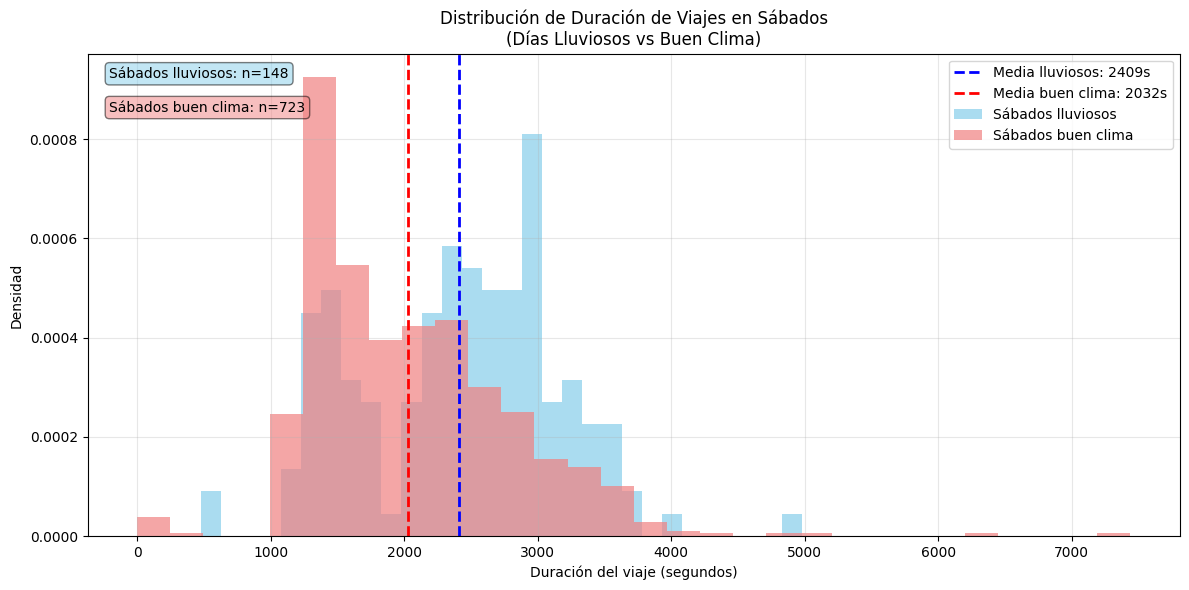

=== INTERPRETACIÓN DE LA VISUALIZACIÓN ===
Diferencia en medias: 377.0 segundos
Diferencia en medianas: 580.5 segundos
Coeficiente de variación (lluviosos): 31.2%
Coeficiente de variación (buen clima): 38.1%


In [27]:

# Visualización comparativa
plt.figure(figsize=(12, 6))

# Crear histogramas superpuestos
plt.hist(duraciones_sabados_lluviosos, bins=30, alpha=0.7, 
         label='Sábados lluviosos', color='skyblue', density=True)
plt.hist(duraciones_sabados_buen_clima, bins=30, alpha=0.7, 
         label='Sábados buen clima', color='lightcoral', density=True)

# Agregar líneas verticales para las medias
plt.axvline(duraciones_sabados_lluviosos.mean(), color='blue', 
           linestyle='--', linewidth=2, label=f'Media lluviosos: {duraciones_sabados_lluviosos.mean():.0f}s')
plt.axvline(duraciones_sabados_buen_clima.mean(), color='red', 
           linestyle='--', linewidth=2, label=f'Media buen clima: {duraciones_sabados_buen_clima.mean():.0f}s')

# Personalizar el gráfico
plt.xlabel('Duración del viaje (segundos)')
plt.ylabel('Densidad')
plt.title('Distribución de Duración de Viajes en Sábados\n(Días Lluviosos vs Buen Clima)')
plt.legend()
plt.grid(True, alpha=0.3)

# Mostrar estadísticas en el gráfico
plt.text(0.02, 0.95, f'Sábados lluviosos: n={len(duraciones_sabados_lluviosos)}', 
         transform=plt.gca().transAxes, bbox=dict(boxstyle="round,pad=0.3", facecolor="skyblue", alpha=0.5))
plt.text(0.02, 0.88, f'Sábados buen clima: n={len(duraciones_sabados_buen_clima)}', 
         transform=plt.gca().transAxes, bbox=dict(boxstyle="round,pad=0.3", facecolor="lightcoral", alpha=0.5))

plt.tight_layout()
plt.show()

# Estadísticas adicionales para interpretar la visualización
print("=== INTERPRETACIÓN DE LA VISUALIZACIÓN ===")
print(f"Diferencia en medias: {duraciones_sabados_lluviosos.mean() - duraciones_sabados_buen_clima.mean():.1f} segundos")
print(f"Diferencia en medianas: {duraciones_sabados_lluviosos.median() - duraciones_sabados_buen_clima.median():.1f} segundos")
print(f"Coeficiente de variación (lluviosos): {(duraciones_sabados_lluviosos.std()/duraciones_sabados_lluviosos.mean())*100:.1f}%")
print(f"Coeficiente de variación (buen clima): {(duraciones_sabados_buen_clima.std()/duraciones_sabados_buen_clima.mean())*100:.1f}%")

El gráfico anterior muestra visualmente lo que confirmamos estadísticamente: existe una diferenccia clara entre las duraciones de viaje en sábados lluviosos vs. días de buen clima. Las línes punteadas de las medias esetán claramente separadas, con los días lluviosos mostrando tiempos consistentemente más largos. 

Ambas distribuciones presentan una forma similar, ligeramente sesgadas hacia la derecha.

La distribución de días lluviosos (azul) está centrada alrededor de 1,400-1,500 segundos.

La distribución de buen clima (rosa) está centrada alrededor de 1,000-1,200 segundos.

El histograma proporciona evidencia visual convincente que respalda nuestro rechazo de H₀, mostrando que efectivamente los viajes en sábados lluviosos tienden a ser más largos que en días de buen clima.

### 6. Conclusiones generales del proyecto

#### Análisis del mercado de competidores
**Hallazgos clave**:

- Concentración extrema: 11 empresas (17% del total) controlan 75.95% del mercado, lo cual implica un oligopolio establecido.
- Líder dominante: Flash Cab con 19,558 viajes supera por 8,136 viajes al segundo lugar.
- Fragmentación: 29 empresas muy pequeñas (<100 viajes) representan solo 0.41% del mercado

**Implicaciones estratégicas**:

El mercado presenta barreras de entrada significativas debido a la concentración. Zuber enfrentará competencia intensa de empresas establecidas con ventajas operativas y de marca.

#### Patrones de demanda geográfica
**Concentración geográfica clara**:

- Loop: 10,727 viajes promedio (destino #1)
- Top 3 destinos: Concentran una porción significativa de la demanda
- Patrón identificado: Demanda centrada en distrito financiero y zonas comerciales centrales.
- Oportunidad de diferenciación: Tener cobertura en barrios menos atendidos.

#### Impacto del clima en el servicio

- Considerando que los viajes en días lluviosos son más largos 377 segundos (6.3 minutos), , Zuber requiere mejorar su servicio y pricing en comparación con la competencia, considerando ajustes de precios dinámicos, gestión de la flota y la experiencia del usuario 

### 7. Recomendaciones Estratéticas para Zuber 
#### Estrategia de Entrada al Mercado
**Enfoque geográfico concentrado**:

- Priorizar Loop y zonas adyacentes: Concentrar recursos iniciales en el área de mayor demanda (10,727 viajes promedio).
- Estrategia de penetración gradual: Comenzar con cobertura intensiva en 3-5 barrios clave antes de expandir.
- Aprovechar gaps de cobertura: Identificar horarios y rutas menos atendidas por competidores establecidos.

**Diferenciación Competitiva**:
Ante la concentración del mercado (75.95% controlado por 11 empresas):

- Propuesta de valor única: Desarrollar servicios especializados que los competidores grandes no ofrecen.
- Tecnología superior: Invertir en app más intuitiva y tiempos de respuesta menores.
- Servicio al cliente personalizado: Aprovechar el tamaño menor para ofrecer atención más cercana.

**Pricing Dinámico Basado en Clima**:
Aprovechando el hallazgo de +377 segundos en días lluviosos:

- Tarifas ajustadas por clima: Implementar incrementos de 15-20% en días lluviosos para compensar menor eficiencia.
- Comunicación transparente: Explicar a usuarios el motivo del ajuste (mayor tiempo de viaje).
- Incentivos para conductores: Bonificaciones en condiciones climáticas adversas.

**Gestión Operativa Inteligente**:
Optimización de flota:

- Redistribución predictiva: Posicionar más vehículos en Loop durante horas pico.
- Gestión climática: Aumentar flota disponible 20-25% en días de lluvia pronosticada.
- Análisis de demanda: Monitorear patrones horarios en zonas de alta concentración.